In [2]:
from plistlib import loads

import anndata
from anndata import AnnData
import pandas as pd
import rectanglepy as rp
from scipy.io import mmread
import helper

# Figure 3

## Figure 3A

In [ ]:

cell_palette = {
    'Brca': '#66C2A5',
    'Luad': '#FC8D62',
    'Lusc': '#8DA0CB',
    'CPE': '#FC8D62',
    'B cells': '#66C2A5',
    'Macrophages': '#FC8D62',
    'Macrophages-Monocytes': '#FC8D62',
    "Macrophage alveolar": '#FC8D62',
    'mDC': '#8DA0CB',
    'mDCs': '#8DA0CB',
    'Monocytes': '#E78AC3',
    'Monocytes classical': '#E580C0',
    'Monocytes non-classical': '#D085B9',
    'NK cells': '#DDD700',
    'T and NK cells': '#DDD700',
    'T cells': '#FFD92F',
    'T cells CD4 conv': '#B3B3B3',
    'T cells CD4': '#B3B3B3',
    'T cells CD4 non-reg': '#B3B3B3',
    'T cells CD4 Total': '#B3B3B3',
    'T cells CD8': '#A6D854',
    'T cells CD8 activated': '#A5D753',
    'T cells CD8 naive': '#A0D04B',
    'T cells CD8 t.e.': '#A0A410',
    'T cells NK-like': '#DBD500',
    'Tregs': '#52A0A0',
    'pDC': '#E5C494',
    'pDCs': '#E5C490',
    'cDC1': '#A3C292',
    'cDC2': '#A1C090',
    'Neutrophils': '#B3B3B3',
    'Stromal cells': '#66C2A5',
    'Plasma cells': '#FC8D62',
    'ILC': '#8DA0CB',
    'Platelet': '#E78AC3',
    'all': '#000000'
}

In [1]:
import pandas as pd
import helper
import importlib
import rectanglepy as rp
import anndata
lambrechts_folder = '../data/fig3/pseudo_bulk_resolution/lambrechts_resolution_analysis_sim'

In [5]:
# you can find a zipped version of the file under: https://figshare.com/account/articles/32521659
lambrechts_counts = pd.read_csv(lambrechts_folder + '/lambrecht_counts.csv.zip', index_col=0)

KeyboardInterrupt: 

In [2]:
annotations_normal =pd.read_csv(lambrechts_folder + '/lambrechts_annotations_normal.csv', index_col=0).squeeze()
annotations_coarse = pd.read_csv(lambrechts_folder + '/lambrechts_annotations_coarse.csv', index_col=0).squeeze()
annotations_fine = pd.read_csv(lambrechts_folder + '/lambrechts_annotations_fine.csv', index_col=0).squeeze()

In [3]:
annotations_fine.index = lambrechts_counts.columns
annotations_coarse.index = lambrechts_counts.columns
annotations_normal.index = lambrechts_counts.columns
# rename column 'x' to 'cell_type'
annotations_fine.name = 'cell_type'
annotations_normal.name = 'cell_type'
annotations_coarse.name = 'cell_type'

NameError: name 'lambrechts_counts' is not defined

In [ ]:
lambrechts_adata = anndata.AnnData(X=lambrechts_counts.T, obs=annotations_fine.to_frame(name="cell_type"))
for i in range(1,6):
    bulks = pd.read_csv(lambrechts_folder + f'/replicate_{i}/lambrechts_resolution_analysis_sim_tpm.csv', index_col=0)
    estimations, signature = rp.rectangle(lambrechts_adata, bulks.T)
    estimations.to_csv(lambrechts_folder + f'/replicate_{i}/estimations_fine.csv')

In [ ]:

lambrechts_adata = anndata.AnnData(X=lambrechts_counts.T, obs=annotations_coarse.to_frame(name="cell_type"))
for i in range(1,6):
    bulks = pd.read_csv(lambrechts_folder + f'/replicate_{i}/lambrechts_resolution_analysis_sim_tpm.csv', index_col=0)
    estimations, signature = rp.rectangle(lambrechts_adata, bulks.T)
    estimations.to_csv(lambrechts_folder + f'/replicate_{i}/estimations_coarse.csv')

In [ ]:

lambrechts_adata = anndata.AnnData(X=lambrechts_counts.T, obs=annotations_normal.to_frame(name="cell_type"))
for i in range(1,6):
    bulks = pd.read_csv(lambrechts_folder + f'/replicate_{i}/lambrechts_resolution_analysis_sim_tpm.csv', index_col=0)
    estimations, signature = rp.rectangle(lambrechts_adata, bulks.T)
    estimations.to_csv(lambrechts_folder + f'/replicate_{i}/estimations_normal.csv')


In [4]:
lambrechts_folder = '../data/fig3/pseudo_bulk_resolution/lambrechts_resolution_analysis_sim'

lambrechts_fine_estimations = []
lambrechts_fine_true =[]
lambrechts_normal_estimations = []
lambrechts_normal_true =[]
lambrechts_coarse_estimations = []
lambrechts_coarse_true =[]
for i in range(1,6):
    fine_estimation = pd.read_csv(lambrechts_folder + f'/replicate_{i}/estimations_fine.csv', index_col=0)
    fine_estimation = fine_estimation.drop('Unknown', axis=1)
    fine_true = pd.read_csv(lambrechts_folder + f'/replicate_{i}/lambrechts_resolution_analysis_sim_fine_annot_facs.csv', index_col=0)
    normal_estimation = pd.read_csv(lambrechts_folder + f'/replicate_{i}/estimations_normal.csv', index_col=0)
    normal_estimation = normal_estimation.drop('Unknown', axis=1)
    normal_true = pd.read_csv(lambrechts_folder + f'/replicate_{i}/lambrechts_resolution_analysis_sim_normal_annot_facs.csv', index_col=0)
    coarse_estimation = pd.read_csv(lambrechts_folder + f'/replicate_{i}/estimations_coarse.csv', index_col=0)
    coarse_estimation = coarse_estimation.drop('Unknown', axis=1)
    coarse_true = pd.read_csv(lambrechts_folder + f'/replicate_{i}/lambrechts_resolution_analysis_sim_coarse_annot_facs.csv', index_col=0)
    lambrechts_fine_estimations.append(fine_estimation)
    lambrechts_normal_estimations.append(normal_estimation)
    lambrechts_coarse_estimations.append(coarse_estimation)
    lambrechts_fine_true.append(fine_true)
    lambrechts_normal_true.append(normal_true)
    lambrechts_coarse_true.append(coarse_true)

In [5]:
lambrechts_true = lambrechts_coarse_true[0]
lambrechts_estimation = lambrechts_coarse_estimations[0].T
    # sort columns and index to match
lambrechts_true = lambrechts_true.sort_index().sort_index(axis=1)
lambrechts_estimation = lambrechts_estimation.sort_index().sort_index(axis=1)
lambrechts_estimation.index = lambrechts_estimation.index.map(lambda x: str(x).replace("_", " "))


lambrechts

In [7]:

lambrechts_fine_evaluations = []
lambrechts_fine_evalutaions_cell_types = []
lambrechts_normal_evaluations = []
lambrechts_normal_evaluations_cell_types = []
lambrechts_coarse_evaluations = []
lambrechts_coarse_evaluations_cell_types = []
lambrechts_fine_grouped_coarse_evaluations_cell_types = []
lambrechts_fine_grouped_coarse_cell_types_list = []

lambrechts_eval_mappings = pd.read_csv('../data/fig3/pseudo_bulk_resolution/mappings.csv')

def _normalize_label(label):
    return ' '.join(str(label).replace('_', ' ').replace('-', ' ').replace('.', ' ').replace('+', ' ').split()).lower()

lambrechts_eval_coarse_norm_to_coarse = {
    _normalize_label(coarse): coarse for coarse in lambrechts_eval_mappings['Coarse'].drop_duplicates()
}
lambrechts_eval_fine_norm_to_coarse = {
    _normalize_label(fine): coarse for fine, coarse in zip(lambrechts_eval_mappings['Fine'], lambrechts_eval_mappings['Coarse'])
}
lambrechts_eval_normal_norm_to_coarse = {
    _normalize_label(normal): coarse for normal, coarse in zip(lambrechts_eval_mappings['Normal'], lambrechts_eval_mappings['Coarse'])
}
lambrechts_eval_alias_to_coarse = {
    'macrophage alveolar': 'Macrophages-Monocytes',
    'macrophages alveolar': 'Macrophages-Monocytes',
}

def _lambrechts_coarse_for_label(label):
    norm = _normalize_label(label)
    return (
        lambrechts_eval_alias_to_coarse.get(norm)
        or lambrechts_eval_fine_norm_to_coarse.get(norm)
        or lambrechts_eval_normal_norm_to_coarse.get(norm)
        or lambrechts_eval_coarse_norm_to_coarse.get(norm)
        or str(label).replace('_', ' ')
    )

def _group_to_coarse(df):
    grouped_df = df.copy()
    grouped_df.index = grouped_df.index.map(lambda x: str(x).replace('_', ' '))
    grouped_df['coarse'] = grouped_df.index.map(_lambrechts_coarse_for_label)
    grouped_df = grouped_df.groupby('coarse').sum(numeric_only=True)
    return grouped_df.sort_index().sort_index(axis=1)

fine_cell_types = None
normal_cell_types = None
coarse_cell_types = None
for i in range(5):
    print(i)
    lambrechts_true = lambrechts_fine_true[i]
    lambrechts_estimation = lambrechts_fine_estimations[i].T
    # sort columns and index to match
    lambrechts_true = lambrechts_true.sort_index().sort_index(axis=1)
    lambrechts_estimation = lambrechts_estimation.sort_index().sort_index(axis=1)
    fine_cell_types = lambrechts_estimation.index
    fine_evaluation = helper.create_evaluation_df(lambrechts_true, lambrechts_estimation)
    rsme, r, p = helper.evaulate_total_df(fine_evaluation)
    lambrechts_fine_evaluations.append((rsme, r, p))
    rsmes, rs, ps = helper.evaluate_by_cell_type(lambrechts_true, lambrechts_estimation)
    lambrechts_fine_evalutaions_cell_types.append((rsmes, rs, ps))

    lambrechts_true_grouped = _group_to_coarse(lambrechts_true)
    lambrechts_estimation_grouped = _group_to_coarse(lambrechts_estimation)
    lambrechts_true_grouped, lambrechts_estimation_grouped = helper.match_dfs(lambrechts_true_grouped, lambrechts_estimation_grouped)
    grouped_cell_types = lambrechts_estimation_grouped.index
    rsmes, ps, rs = helper.evaluate_by_cell_type(lambrechts_true_grouped, lambrechts_estimation_grouped)
    lambrechts_fine_grouped_coarse_evaluations_cell_types.append((rsmes, rs, ps))
    lambrechts_fine_grouped_coarse_cell_types_list.append(grouped_cell_types)

    lambrechts_true = lambrechts_normal_true[i]
    lambrechts_estimation = lambrechts_normal_estimations[i].T
    lambrechts_estimation.index = lambrechts_estimation.index.map(lambda x: str(x).replace("_", " "))
    lambrechts_estimation = lambrechts_estimation[lambrechts_estimation.index != "Tregs"]
    # macrophae is macrophage and macrophage alveolar  summed then remove macrophage alveolar
    lambrechts_true = lambrechts_true.T
    lambrechts_true["Macrophages"] = lambrechts_true["Macrophages"] + lambrechts_true["Macrophage alveolar"]
    lambrechts_true = lambrechts_true.T
    lambrechts_true = lambrechts_true[lambrechts_true.index != "Macrophage alveolar"]

    # sort columns and index to match
# sort columns and index to match
    lambrechts_true = lambrechts_true.sort_index().sort_index(axis=1)
    lambrechts_estimation = lambrechts_estimation.sort_index().sort_index(axis=1)

    normal_cell_types = lambrechts_estimation.index
    normal_evaluation = helper.create_evaluation_df(lambrechts_true, lambrechts_estimation)
    rsme, r, p = helper.evaulate_total_df(normal_evaluation)
    lambrechts_normal_evaluations.append((rsme, r, p))
    rsmes, rs, ps = helper.evaluate_by_cell_type(lambrechts_true, lambrechts_estimation)
    lambrechts_normal_evaluations_cell_types.append((rsmes, rs, ps))

    lambrechts_true = lambrechts_coarse_true[i]
    lambrechts_estimation = lambrechts_coarse_estimations[i].T
    # sort columns and index to match
    lambrechts_estimation.index = lambrechts_estimation.index.map(lambda x: str(x).replace("_", " "))
    lambrechts_true = lambrechts_true.T
    lambrechts_true["Macrophages-Monocytes"] = lambrechts_true["Macrophages-Monocytes"] + lambrechts_true["Macrophage alveolar"]
    lambrechts_true = lambrechts_true.T
    lambrechts_true = lambrechts_true[lambrechts_true.index != "Macrophage alveolar"]
    lambrechts_true = lambrechts_true.sort_index().sort_index(axis=1)
    lambrechts_estimation = lambrechts_estimation.sort_index().sort_index(axis=1)
    coarse_cell_types = lambrechts_estimation.index
    coarse_evaluation = helper.create_evaluation_df(lambrechts_true, lambrechts_estimation)
    rsme, r, p = helper.evaulate_total_df(coarse_evaluation)
    lambrechts_coarse_evaluations.append((rsme, r, p))
    rsmes, rs, ps = helper.evaluate_by_cell_type(lambrechts_true, lambrechts_estimation)
    lambrechts_coarse_evaluations_cell_types.append((rsmes, rs, ps))

0
1
2
3
4


In [8]:

# average values
lambrechts_fine_rsmes = [x[0] for x in lambrechts_fine_evaluations]
lambrechts_fine_rsme_avg = sum(lambrechts_fine_rsmes) / len(lambrechts_fine_rsmes)
lambrechts_fine_r_values = [x[1] for x in lambrechts_fine_evaluations]
lambrechts_fine_r_avg = sum(lambrechts_fine_r_values) / len(lambrechts_fine_r_values)
lambrechts_normal_rsmes = [x[0] for x in lambrechts_normal_evaluations]
lambrechts_normal_rsme_avg = sum(lambrechts_normal_rsmes) / len(lambrechts_normal_rsmes)
lambrechts_normal_r_values = [x[1] for x in lambrechts_normal_evaluations]
lambrechts_normal_r_avg = sum(lambrechts_normal_r_values) / len(lambrechts_normal_r_values)
lambrechts_coarse_rsmes = [x[0] for x in lambrechts_coarse_evaluations]
lambrechts_coarse_rsme_avg = sum(lambrechts_coarse_rsmes) / len(lambrechts_coarse_rsmes)
lambrechts_coarse_r_values = [x[1] for x in lambrechts_coarse_evaluations]
lambrechts_coarse_r_avg = sum(lambrechts_coarse_r_values) / len(lambrechts_coarse_r_values)

lambrechts_fine_rsmes_cell = [x[0] for x in lambrechts_fine_evalutaions_cell_types]
lambrechts_fine_rsme_cell_avg = pd.DataFrame(lambrechts_fine_rsmes_cell).mean()
# set index to fine_cell_types
lambrechts_fine_rsme_cell_avg.index = fine_cell_types
lambrechts_fine_r_cell = [x[2] for x in lambrechts_fine_evalutaions_cell_types]
lambrechts_fine_r_cell_avg = pd.DataFrame(lambrechts_fine_r_cell).mean()
# set index to fine_cell_types
lambrechts_fine_r_cell_avg.index = fine_cell_types
lambrechts_normal_rsmes_cell = [x[0] for x in lambrechts_normal_evaluations_cell_types]
lambrechts_normal_rsme_cell_avg = pd.DataFrame(lambrechts_normal_rsmes_cell).mean()
lambrechts_normal_rsme_cell_avg.index = normal_cell_types
lambrechts_normal_r_cell = [x[2] for x in lambrechts_normal_evaluations_cell_types]
lambrechts_normal_r_cell_avg = pd.DataFrame(lambrechts_normal_r_cell).mean()
lambrechts_normal_r_cell_avg.index = normal_cell_types
lambrechts_coarse_rsmes_cell = [x[0] for x in lambrechts_coarse_evaluations_cell_types]
lambrechts_coarse_rsme_cell_avg = pd.DataFrame(lambrechts_coarse_rsmes_cell).mean()
lambrechts_coarse_rsme_cell_avg.index = coarse_cell_types
lambrechts_coarse_r_cell = [x[2] for x in lambrechts_coarse_evaluations_cell_types]
lambrechts_coarse_r_cell_avg = pd.DataFrame(lambrechts_coarse_r_cell).mean()
lambrechts_coarse_r_cell_avg.index = coarse_cell_types

lambrechts_fine_grouped_coarse_rsme_series = []
lambrechts_fine_grouped_coarse_r_series = []
for (rsmes, rs, _ps), cell_types in zip(
    lambrechts_fine_grouped_coarse_evaluations_cell_types,
    lambrechts_fine_grouped_coarse_cell_types_list,
):
    lambrechts_fine_grouped_coarse_rsme_series.append(pd.Series(rsmes, index=cell_types))
    lambrechts_fine_grouped_coarse_r_series.append(pd.Series(rs, index=cell_types))
lambrechts_fine_grouped_coarse_rsme_cell_avg = pd.concat(lambrechts_fine_grouped_coarse_rsme_series, axis=1).mean(axis=1)
lambrechts_fine_grouped_coarse_r_cell_avg = pd.concat(lambrechts_fine_grouped_coarse_r_series, axis=1).mean(axis=1)

In [29]:
# plot results
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

mappings = pd.read_csv('../data/fig3/pseudo_bulk_resolution/mappings.csv')

def normalize_label(label):
    return ' '.join(str(label).replace('_', ' ').replace('-', ' ').replace('.', ' ').replace('+', ' ').split()).lower()

coarse_color_map = mappings.drop_duplicates('Coarse').set_index('Coarse')['colors'].to_dict()
coarse_norm_to_coarse = {
    normalize_label(coarse): coarse for coarse in mappings['Coarse'].drop_duplicates()
}
fine_norm_to_coarse = {
    normalize_label(fine): coarse for fine, coarse in zip(mappings['Fine'], mappings['Coarse'])
}
normal_norm_to_coarse = {
    normalize_label(normal): coarse for normal, coarse in zip(mappings['Normal'], mappings['Coarse'])
}

label_alias_to_coarse = {
    'macrophage alveolar': 'Macrophages-Monocytes',
    'macrophages alveolar': 'Macrophages-Monocytes',
}

def coarse_for_label(label):
    norm = normalize_label(label)
    return (
        label_alias_to_coarse.get(norm)
        or fine_norm_to_coarse.get(norm)
        or normal_norm_to_coarse.get(norm)
        or coarse_norm_to_coarse.get(norm)
    )

def build_plot_df(corr_series, rmse_series):
    df = corr_series.to_frame(name='Correlation').join(rmse_series.to_frame(name='RMSE')).reset_index()
    df = df.rename(columns={df.columns[0]: 'cell_type'})
    df['coarse'] = df['cell_type'].map(coarse_for_label)
    df.loc[df['coarse'].isna(), 'coarse'] = df.loc[df['coarse'].isna(), 'cell_type']
    return df

def build_grouped_coarse_plot_df(corr_series, rmse_series):
    return build_plot_df(corr_series, rmse_series)

def build_coarse_palette(values):
    return {c: coarse_color_map.get(c, '#999999') for c in pd.Series(values).dropna().unique()}

def add_coarse_legend(ax, coarse_values):
    handles = [
        Line2D([0], [0], marker='o', linestyle='None', markersize=6,
               markerfacecolor=coarse_color_map[c], markeredgecolor=coarse_color_map[c], label=c)
        for c in coarse_values if c in coarse_color_map
    ]
    ax.legend(handles=handles, bbox_to_anchor=(1.15, 1), loc=2, borderaxespad=0., ncol=1, title='Coarse')

normal_df = build_plot_df(lambrechts_normal_r_cell_avg, lambrechts_normal_rsme_cell_avg)
normal_palette = {
    row.cell_type: coarse_color_map.get(row.coarse, '#999999')
    for row in normal_df.itertuples(index=False)
}



In [28]:
fine_df = build_plot_df(lambrechts_fine_r_cell_avg, lambrechts_fine_rsme_cell_avg)
fine_palette = {
    row.cell_type: coarse_color_map.get(row.coarse, '#999999')
    for row in fine_df.itertuples(index=False)
}


fine_grouped_coarse_df = build_plot_df(lambrechts_fine_grouped_coarse_r_cell_avg, lambrechts_fine_grouped_coarse_rsme_cell_avg)





In [27]:
coarse_df = build_plot_df(lambrechts_coarse_r_cell_avg, lambrechts_coarse_rsme_cell_avg)





# Wu resolution analysis

In [15]:
import pandas as pd
import helper
import rectanglepy as rp
import anndata
wu_folder = '../data/fig3/pseudo_bulk_resolution/wu_resolution_analysis_sim'

In [14]:
# you can find a zipped version of the file under: https://figshare.com/account/articles/32521659
wu_counts = pd.read_csv(wu_folder + '/wu_counts.csv.zip', index_col=0)

KeyboardInterrupt: 

In [16]:

annotations_normal = pd.read_csv(wu_folder + '/wu_annotations_normal.csv', index_col=0).squeeze()
annotations_coarse = pd.read_csv(wu_folder + '/wu_annotations_coarse.csv', index_col=0).squeeze()
annotations_fine = pd.read_csv(wu_folder + '/wu_annotations_fine.csv', index_col=0).squeeze()
annotations_fine.index = wu_counts.columns
annotations_coarse.index = wu_counts.columns
annotations_normal.index = wu_counts.columns
# rename column 'x' to 'cell_type'

NameError: name 'wu_counts' is not defined

In [17]:
import pandas as pd
import helper
import rectanglepy as rp
import anndata
wu_folder = '../data/fig3/pseudo_bulk_resolution/wu_resolution_analysis_sim'

In [18]:

# load anndata from h5ad file
wu_adata = anndata.read_h5ad(wu_folder + '/wu_adata_sparse.h5ad')
annotations_normal = pd.read_csv(wu_folder + '/wu_annotations_normal.csv', index_col=0).squeeze()
annotations_coarse = pd.read_csv(wu_folder + '/wu_annotations_coarse.csv', index_col=0).squeeze()
annotations_fine = pd.read_csv(wu_folder + '/wu_annotations_fine.csv', index_col=0).squeeze()
# take index from andata and set it to annotations
annotations_fine.index = wu_adata.obs_names
annotations_coarse.index = wu_adata.obs_names
annotations_normal.index = wu_adata.obs_names
annotations_fine.name = 'cell_type'
annotations_normal.name = 'cell_type'
annotations_coarse.name = 'cell_type'

# write anndata to h5ad file


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '../data/fig3/pseudo_bulk_resolution/wu_resolution_analysis_sim/wu_adata_sparse.h5ad', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
#
for i in range(1, 6):
    bulks = pd.read_csv(wu_folder + f'/replicate_{i}/wu_resolution_analysis_sim_tpm.csv', index_col=0)
    estimations, signature = rp.rectangle(wu_adata, bulks.T)
    estimations.to_csv(wu_folder + f'/replicate_{i}/estimations_fine.csv')

In [ ]:

# change obs to coarse annotation
wu_adata.obs = annotations_coarse.to_frame(name="cell_type")
for i in range(1, 6):
    bulks = pd.read_csv(wu_folder + f'/replicate_{i}/wu_resolution_analysis_sim_tpm.csv', index_col=0)
    estimations, signature = rp.rectangle(wu_adata, bulks.T)
    estimations.to_csv(wu_folder + f'/replicate_{i}/estimations_coarse.csv')

wu_adata.obs = annotations_normal.to_frame(name="cell_type")
for i in range(1, 6):
    bulks = pd.read_csv(wu_folder + f'/replicate_{i}/wu_resolution_analysis_sim_tpm.csv', index_col=0)
    estimations, signature = rp.rectangle(wu_adata, bulks.T)
    estimations.to_csv(wu_folder + f'/replicate_{i}/estimations_normal.csv')


In [19]:
import pandas as pd
import helper


wu_fine_estimations = []
wu_fine_true =[]
wu_normal_estimations = []
wu_normal_true =[]
wu_coarse_estimations = []
wu_coarse_true =[]
for i in range(1,6):
    fine_estimation = pd.read_csv(wu_folder + f'/replicate_{i}/estimations_fine.csv', index_col=0)
    fine_estimation = fine_estimation.drop('Unknown', axis=1)
    fine_true = pd.read_csv(wu_folder + f'/replicate_{i}/wu_resolution_analysis_sim_fine_annot_facs.csv', index_col=0)
    normal_estimation = pd.read_csv(wu_folder + f'/replicate_{i}/estimations_normal.csv', index_col=0)
    normal_estimation = normal_estimation.drop('Unknown', axis=1)
    normal_true = pd.read_csv(wu_folder + f'/replicate_{i}/wu_resolution_analysis_sim_normal_annot_facs.csv', index_col=0)
    coarse_estimation = pd.read_csv(wu_folder + f'/replicate_{i}/estimations_coarse.csv', index_col=0)
    coarse_estimation = coarse_estimation.drop('Unknown', axis=1)
    coarse_true = pd.read_csv(wu_folder + f'/replicate_{i}/wu_resolution_analysis_sim_coarse_annot_facs.csv', index_col=0)
    wu_fine_estimations.append(fine_estimation)
    wu_normal_estimations.append(normal_estimation)
    wu_coarse_estimations.append(coarse_estimation)
    wu_fine_true.append(fine_true)
    wu_normal_true.append(normal_true)
    wu_coarse_true.append(coarse_true)

wu_fine_evaluations = []
wu_fine_evalutaions_cell_types = []
wu_normal_evaluations = []
wu_normal_evaluations_cell_types = []
wu_coarse_evaluations = []
wu_coarse_evaluations_cell_types = []
wu_fine_grouped_coarse_evaluations_cell_types = []
wu_fine_grouped_coarse_cell_types_list = []

wu_eval_mappings = pd.read_csv('../data/fig3/pseudo_bulk_resolution/wu_resolution_analysis_sim/wu_celltype_mappings.csv')

def _normalize_wu_label(label):
    return ' '.join(str(label).replace('_', ' ').replace('-', ' ').replace('.', ' ').replace('+', ' ').split()).lower()

wu_eval_coarse_norm_to_coarse = {
    _normalize_wu_label(coarse): coarse for coarse in wu_eval_mappings['Coarse'].drop_duplicates()
}
wu_eval_fine_norm_to_coarse = {
    _normalize_wu_label(fine): coarse for fine, coarse in zip(wu_eval_mappings['Fine'], wu_eval_mappings['Coarse'])
}
wu_eval_normal_norm_to_coarse = {
    _normalize_wu_label(normal): coarse for normal, coarse in zip(wu_eval_mappings['Normal'], wu_eval_mappings['Coarse'])
}

def _wu_coarse_for_label_eval(label):
    norm = _normalize_wu_label(label)
    return (
        wu_eval_fine_norm_to_coarse.get(norm)
        or wu_eval_normal_norm_to_coarse.get(norm)
        or wu_eval_coarse_norm_to_coarse.get(norm)
        or str(label)
    )

def _group_wu_to_coarse(df):
    grouped_df = df.copy()
    grouped_df.index = grouped_df.index.map(lambda x: str(x))
    grouped_df['coarse'] = grouped_df.index.map(_wu_coarse_for_label_eval)
    grouped_df = grouped_df.groupby('coarse').sum(numeric_only=True)
    return grouped_df.sort_index().sort_index(axis=1)

fine_cell_types = None
normal_cell_types = None
coarse_cell_types = None
for i in range(5):
    wu_true = wu_fine_true[i]
    wu_estimation = wu_fine_estimations[i].T
    # sort columns and index to match
    wu_true = wu_true.sort_index().sort_index(axis=1)
    wu_estimation = wu_estimation.sort_index().sort_index(axis=1)
    fine_cell_types = wu_estimation.index
    fine_evaluation = helper.create_evaluation_df(wu_true, wu_estimation)
    rsme, r, p = helper.evaulate_total_df(fine_evaluation)
    wu_fine_evaluations.append((rsme, r, p))
    rsmes, rs, ps = helper.evaluate_by_cell_type(wu_true, wu_estimation)
    wu_fine_evalutaions_cell_types.append((rsmes, rs, ps))

    wu_true_grouped = _group_wu_to_coarse(wu_true)
    wu_estimation_grouped = _group_wu_to_coarse(wu_estimation)
    wu_true_grouped, wu_estimation_grouped = helper.match_dfs(wu_true_grouped, wu_estimation_grouped)
    grouped_cell_types = wu_estimation_grouped.index
    rsmes, ps, rs = helper.evaluate_by_cell_type(wu_true_grouped, wu_estimation_grouped)
    wu_fine_grouped_coarse_evaluations_cell_types.append((rsmes, rs, ps))
    wu_fine_grouped_coarse_cell_types_list.append(grouped_cell_types)

    wu_true = wu_normal_true[i]
    wu_estimation = wu_normal_estimations[i].T
    # sort columns and index to match
    wu_true = wu_true.sort_index().sort_index(axis=1)
    wu_estimation = wu_estimation.sort_index().sort_index(axis=1)
    normal_cell_types = wu_estimation.index
    normal_evaluation = helper.create_evaluation_df(wu_true, wu_estimation)
    rsme, r, p = helper.evaulate_total_df(normal_evaluation)
    wu_normal_evaluations.append((rsme, r, p))
    rsmes, rs, ps = helper.evaluate_by_cell_type(wu_true, wu_estimation)
    wu_normal_evaluations_cell_types.append((rsmes, rs, ps))

    wu_true = wu_coarse_true[i]
    wu_estimation = wu_coarse_estimations[i].T
    # sort columns and index to match
    wu_true = wu_true.sort_index().sort_index(axis=1)
    wu_estimation = wu_estimation.sort_index().sort_index(axis=1)
    coarse_cell_types = wu_estimation.index
    coarse_evaluation = helper.create_evaluation_df(wu_true, wu_estimation)
    rsme, r, p = helper.evaulate_total_df(coarse_evaluation)
    wu_coarse_evaluations.append((rsme, r, p))
    rsmes, rs, ps = helper.evaluate_by_cell_type(wu_true, wu_estimation)
    wu_coarse_evaluations_cell_types.append((rsmes, rs, ps))

# average values
wu_fine_rsmes = [x[0] for x in wu_fine_evaluations]
wu_fine_rsme_avg = sum(wu_fine_rsmes) / len(wu_fine_rsmes)
wu_fine_r_values = [x[1] for x in wu_fine_evaluations]
wu_fine_r_avg = sum(wu_fine_r_values) / len(wu_fine_r_values)
wu_normal_rsmes = [x[0] for x in wu_normal_evaluations]
wu_normal_rsme_avg = sum(wu_normal_rsmes) / len(wu_normal_rsmes)
wu_normal_r_values = [x[1] for x in wu_normal_evaluations]
wu_normal_r_avg = sum(wu_normal_r_values) / len(wu_normal_r_values)
wu_coarse_rsmes = [x[0] for x in wu_coarse_evaluations]
wu_coarse_rsme_avg = sum(wu_coarse_rsmes) / len(wu_coarse_rsmes)
wu_coarse_r_values = [x[1] for x in wu_coarse_evaluations]
wu_coarse_r_avg = sum(wu_coarse_r_values) / len(wu_coarse_r_values)

wu_fine_rsmes_cell = [x[0] for x in wu_fine_evalutaions_cell_types]
wu_fine_rsme_cell_avg = pd.DataFrame(wu_fine_rsmes_cell).mean()
# set index to fine_cell_types
wu_fine_rsme_cell_avg.index = fine_cell_types
wu_fine_r_cell = [x[2] for x in wu_fine_evalutaions_cell_types]
wu_fine_r_cell_avg = pd.DataFrame(wu_fine_r_cell).mean()
# set index to fine_cell_types
wu_fine_r_cell_avg.index = fine_cell_types
wu_normal_rsmes_cell = [x[0] for x in wu_normal_evaluations_cell_types]
wu_normal_rsme_cell_avg = pd.DataFrame(wu_normal_rsmes_cell).mean()
wu_normal_rsme_cell_avg.index = normal_cell_types
wu_normal_r_cell = [x[2] for x in wu_normal_evaluations_cell_types]
wu_normal_r_cell_avg = pd.DataFrame(wu_normal_r_cell).mean()
wu_normal_r_cell_avg.index = normal_cell_types
wu_coarse_rsmes_cell = [x[0] for x in wu_coarse_evaluations_cell_types]
wu_coarse_rsme_cell_avg = pd.DataFrame(wu_coarse_rsmes_cell).mean()
wu_coarse_rsme_cell_avg.index = coarse_cell_types
wu_coarse_r_cell = [x[2] for x in wu_coarse_evaluations_cell_types]
wu_coarse_r_cell_avg = pd.DataFrame(wu_coarse_r_cell).mean()
wu_coarse_r_cell_avg.index = coarse_cell_types

wu_fine_grouped_coarse_rsme_series = []
wu_fine_grouped_coarse_r_series = []
for (rsmes, rs, _ps), cell_types in zip(
    wu_fine_grouped_coarse_evaluations_cell_types,
    wu_fine_grouped_coarse_cell_types_list,
):
    wu_fine_grouped_coarse_rsme_series.append(pd.Series(rsmes, index=cell_types))
    wu_fine_grouped_coarse_r_series.append(pd.Series(rs, index=cell_types))
wu_fine_grouped_coarse_rsme_cell_avg = pd.concat(wu_fine_grouped_coarse_rsme_series, axis=1).mean(axis=1)
wu_fine_grouped_coarse_r_cell_avg = pd.concat(wu_fine_grouped_coarse_r_series, axis=1).mean(axis=1)

In [26]:
# plot results
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

wu_mappings = pd.read_csv('../data/fig3/pseudo_bulk_resolution/wu_resolution_analysis_sim/wu_celltype_mappings.csv')

def normalize_label(label):
    return ' '.join(str(label).replace('_', ' ').replace('-', ' ').replace('.', ' ').replace('+', ' ').split()).lower()

wu_coarse_color_map = wu_mappings.drop_duplicates('Coarse').set_index('Coarse')['colors'].to_dict()
wu_coarse_norm_to_coarse = {
    normalize_label(coarse): coarse for coarse in wu_mappings['Coarse'].drop_duplicates()
}
wu_fine_norm_to_coarse = {
    normalize_label(fine): coarse for fine, coarse in zip(wu_mappings['Fine'], wu_mappings['Coarse'])
}
wu_normal_norm_to_coarse = {
    normalize_label(normal): coarse for normal, coarse in zip(wu_mappings['Normal'], wu_mappings['Coarse'])
}

def wu_coarse_for_label(label):
    norm = normalize_label(label)
    return (
        wu_fine_norm_to_coarse.get(norm)
        or wu_normal_norm_to_coarse.get(norm)
        or wu_coarse_norm_to_coarse.get(norm)
    )

def build_wu_plot_df(corr_series, rmse_series):
    df = corr_series.to_frame(name='Correlation').join(rmse_series.to_frame(name='RMSE')).reset_index()
    df = df.rename(columns={df.columns[0]: 'cell_type'})
    df['coarse'] = df['cell_type'].map(wu_coarse_for_label)
    df.loc[df['coarse'].isna(), 'coarse'] = df.loc[df['coarse'].isna(), 'cell_type']
    return df

def build_wu_grouped_coarse_plot_df(corr_series, rmse_series):
    return build_wu_plot_df(corr_series, rmse_series)

def build_wu_coarse_palette(values):
    return {c: wu_coarse_color_map.get(c, '#999999') for c in pd.Series(values).dropna().unique()}

def add_wu_coarse_legend(ax, coarse_values):
    handles = [
        Line2D([0], [0], marker='o', linestyle='None', markersize=6,
               markerfacecolor=wu_coarse_color_map[c], markeredgecolor=wu_coarse_color_map[c], label=c)
        for c in coarse_values if c in wu_coarse_color_map
    ]
    ax.legend(handles=handles, bbox_to_anchor=(1.15, 1), loc=2, borderaxespad=0., ncol=1, title='Coarse')

wu_normal_df = build_wu_plot_df(wu_normal_r_cell_avg, wu_normal_rsme_cell_avg)
wu_normal_palette = {
    row.cell_type: wu_coarse_color_map.get(row.coarse, '#999999')
    for row in wu_normal_df.itertuples(index=False)
}



In [25]:
wu_fine_df = build_wu_plot_df(wu_fine_r_cell_avg, wu_fine_rsme_cell_avg)


wu_fine_grouped_coarse_df = build_wu_plot_df(wu_fine_grouped_coarse_r_cell_avg, wu_fine_grouped_coarse_rsme_cell_avg)



In [24]:
wu_coarse_df = build_wu_plot_df(wu_coarse_r_cell_avg, wu_coarse_rsme_cell_avg)


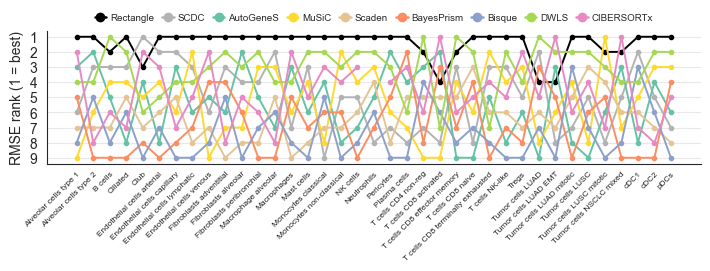

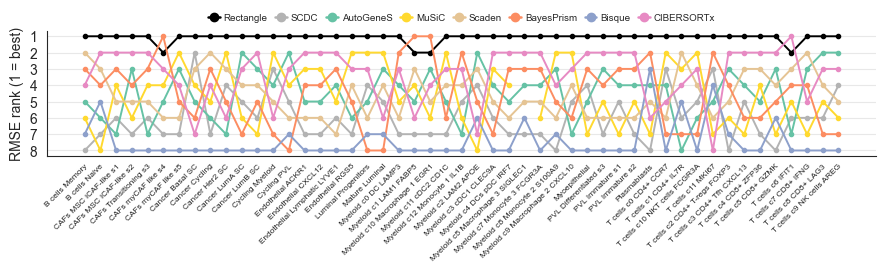

Lambrechts plotted cell types: 37
Wu plotted cell types: 49
RMSE tables written to ../data/fig3/*fine_method_rmse*.csv


,Alveolar cells type 1,Alveolar cells type 2,B cells,Ciliated,Club,Endothelial cells arterial,Endothelial cells capillary,Endothelial cells lymphatic,Endothelial cells venous,Fibroblasts adventitial,...,Tregs,Tumor cells LUAD,Tumor cells LUAD EMT,Tumor cells LUAD mitotic,Tumor cells LUSC,Tumor cells LUSC mitotic,Tumor cells NSCLC mixed,cDC1,cDC2,pDCs
Rectangle,0.001,0.001,0.003,0.001,0.004,0.002,0.002,0.001,0.002,0.002,...,0.006,0.022,0.013,0.002,0.005,0.010,0.003,0.001,0.001,0.001
SCDC,0.009,0.008,0.006,0.004,0.003,0.008,0.008,0.002,0.015,0.006,...,0.013,0.016,0.019,0.020,0.017,0.023,0.012,0.007,0.020,0.008
AutoGeneS,0.004,0.007,0.017,0.022,0.004,0.018,0.010,0.004,0.012,0.009,...,0.015,0.045,0.013,0.021,0.063,0.015,0.006,0.016,0.017,0.007
MuSiC,0.021,0.010,0.014,0.005,0.007,0.009,0.013,0.001,0.036,0.011,...,0.007,0.045,0.015,0.011,0.037,0.009,0.014,0.009,0.014,0.002
Scaden,0.014,0.012,0.020,0.012,0.014,0.015,0.013,0.013,0.020,0.018,...,0.016,0.028,0.015,0.016,0.014,0.014,0.012,0.013,0.028,0.010
BayesPrism,0.008,0.027,0.028,0.045,0.015,0.019,0.022,0.005,0.010,0.008,...,0.021,0.022,0.014,0.050,0.020,0.015,0.036,0.038,0.033,0.003
Bisque,0.020,0.009,0.026,0.015,0.019,0.018,0.034,0.015,0.021,0.008,...,0.028,0.034,0.021,0.009,0.026,0.026,0.015,0.009,0.023,0.012
DWLS,0.006,0.008,0.002,0.002,0.011,0.009,0.011,0.003,0.006,0.005,...,0.009,0.008,0.011,0.003,0.006,0.012,0.009,0.009,0.009,0.001
CIBERSORTx,0.002,0.014,0.018,0.022,0.003,0.008,0.014,0.004,0.003,0.013,...,0.006,0.023,0.009,0.019,0.014,0.019,0.002,0.014,0.032,0.007


,B cells Memory,B cells Naive,CAFs MSC iCAF-like s1,CAFs MSC iCAF-like s2,CAFs Transitioning s3,CAFs myCAF like s4,CAFs myCAF like s5,Cancer Basal SC,Cancer Cycling,Cancer Her2 SC,...,T cells c10 NKT cells FCGR3A,T cells c11 MKI67,T cells c2 CD4+ T-regs FOXP3,T cells c3 CD4+ Tfh CXCL13,T cells c4 CD8+ ZFP36,T cells c5 CD8+ GZMK,T cells c6 IFIT1,T cells c7 CD8+ IFNG,T cells c8 CD8+ LAG3,T cells c9 NK cells AREG
Rectangle,0.008,0.006,0.003,0.005,0.005,0.008,0.003,0.004,0.004,0.002,...,0.003,0.006,0.004,0.003,0.007,0.007,0.008,0.010,0.003,0.003
SCDC,0.023,0.036,0.011,0.022,0.017,0.018,0.017,0.012,0.029,0.013,...,0.016,0.013,0.028,0.017,0.029,0.077,0.019,0.025,0.015,0.015
AutoGeneS,0.022,0.029,0.012,0.010,0.018,0.014,0.010,0.018,0.026,0.033,...,0.017,0.019,0.014,0.017,0.023,0.011,0.020,0.018,0.012,0.012
MuSiC,0.023,0.044,0.010,0.020,0.009,0.010,0.007,0.017,0.025,0.011,...,0.008,0.024,0.020,0.028,0.023,0.066,0.015,0.025,0.015,0.016
Scaden,0.012,0.010,0.011,0.014,0.011,0.015,0.014,0.014,0.016,0.012,...,0.013,0.022,0.017,0.017,0.018,0.014,0.014,0.015,0.013,0.015
BayesPrism,0.019,0.017,0.008,0.012,0.008,0.008,0.012,0.019,0.017,0.025,...,0.018,0.012,0.017,0.018,0.027,0.015,0.014,0.022,0.019,0.019
Bisque,0.023,0.020,0.019,0.032,0.035,0.039,0.034,0.025,0.038,0.034,...,0.020,0.018,0.026,0.028,0.030,0.020,0.038,0.035,0.037,0.028
CIBERSORTx,0.022,0.009,0.006,0.007,0.007,0.009,0.010,0.020,0.021,0.027,...,0.012,0.025,0.009,0.011,0.012,0.007,0.008,0.024,0.013,0.013


In [23]:
# Fine-cell-type RMSE comparison: Rectangle vs deconvolution benchmark methods
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

DATA_ROOT = Path('../data/fig3')
DECONV_ROOT = DATA_ROOT / 'results_resolution_deconvbench'
FIGURE_ROOT = Path('../figures')
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

METHOD_DIR_TO_LABEL = {
    'rectangle': 'Rectangle',
    'autogenes': 'AutoGeneS',
    'bayesprism': 'BayesPrism',
    'bisque': 'Bisque',
    'cibersortx': 'CIBERSORTx',
    'dwls': 'DWLS',
    'music': 'MuSiC',
    'scaden': 'Scaden',
    'scdc': 'SCDC',
}

METHOD_TO_COLOR = {
    'Rectangle': '#000000',
    'SCDC': '#B3B3B3',
    'AutoGeneS': '#66C2A5',
    'MuSiC': '#FFD92F',
    'Scaden': '#E5C494',
    'BayesPrism': '#FC8D62',
    'Bisque': '#8DA0CB',
    'DWLS': '#A6D854',
    'CIBERSORTx': '#E78AC3',
}

METHOD_ORDER = ['Rectangle', 'SCDC', 'AutoGeneS', 'MuSiC', 'Scaden', 'BayesPrism', 'Bisque', 'DWLS', 'CIBERSORTx']


def _read_fraction_csv(path):
    return pd.read_csv(path, index_col=0).apply(pd.to_numeric, errors='coerce')


def _normalize_cell_label(label):
    return ' '.join(str(label).replace('_', ' ').replace('-', ' ').replace('.', ' ').replace('+', ' ').split()).lower()


def _collapse_by_normalized_cell_type(df):
    normalized = [_normalize_cell_label(label) for label in df.index]
    collapsed = df.copy()
    collapsed.index = normalized
    collapsed = collapsed.groupby(level=0).sum(numeric_only=True)
    return collapsed


def _match_fraction_matrices(true_df, estimated_df):
    true_display_labels = {
        _normalize_cell_label(label): str(label).replace('_', ' ')
        for label in true_df.index
    }
    true_norm = _collapse_by_normalized_cell_type(true_df)
    estimated_norm = _collapse_by_normalized_cell_type(estimated_df)

    common_cell_types = sorted(set(true_norm.index).intersection(estimated_norm.index))
    common_samples = sorted(set(true_norm.columns).intersection(estimated_norm.columns))

    true_common = true_norm.loc[common_cell_types, common_samples]
    estimated_common = estimated_norm.loc[common_cell_types, common_samples]
    display_labels = [true_display_labels.get(label, label) for label in common_cell_types]
    true_common.index = display_labels
    estimated_common.index = display_labels
    return true_common, estimated_common


def _rmse_by_cell_type(true_df, estimated_df):
    true_df, estimated_df = _match_fraction_matrices(true_df, estimated_df)
    if true_df.empty or estimated_df.empty:
        return pd.Series(dtype=float)
    return ((estimated_df - true_df) ** 2).mean(axis=1).pow(0.5)


def _collect_deconvbench_rmse(dataset_key, annotation='fine'):
    analysis = f'{dataset_key}_resolution_analysis_sim_{annotation}_annot'
    method_rmse = {}
    for method_dir, method_label in METHOD_DIR_TO_LABEL.items():
        replicate_rmse = []
        for replicate in range(1, 6):
            replicate_folder = DECONV_ROOT / method_dir / analysis / f'replicate_{replicate}'
            if not replicate_folder.exists():
                replicate_rmse = []
                break
            estimated = _read_fraction_csv(replicate_folder / 'deconvolution.csv').T
            true_df = _read_fraction_csv(replicate_folder / 'true_cell_fractions.csv')
            replicate_rmse.append(_rmse_by_cell_type(true_df, estimated))
        if replicate_rmse:
            method_rmse[method_label] = pd.concat(replicate_rmse, axis=1).mean(axis=1)
    return method_rmse


def build_fine_method_rmse_table(dataset_key):
    table = pd.DataFrame(_collect_deconvbench_rmse(dataset_key, 'fine')).T.reindex(METHOD_ORDER).dropna(axis=0, how='all')
    return table.reindex(sorted(table.columns), axis=1)


def _plot_rmse_bump_chart(rmse_table, title, save_path):
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D

    plot_table = rmse_table.dropna(axis=1, how='all')
    cell_types = plot_table.columns.tolist()

    # Rank methods per cell type (1 = best RMSE)
    ranks = plot_table.rank(axis=0, method='first', ascending=True)

    # Dynamic width:
    # tight packing while still avoiding overlap
    max_label_len = max(len(str(c)) for c in cell_types)

    fig_width = max(
        5,
        len(cell_types) * 0.15 + max_label_len * 0.045
    )

    fig, ax = plt.subplots(
        figsize=(fig_width, 2.6),
        constrained_layout=True
    )

    x = np.arange(len(cell_types))

    # Plot lines
    for method in METHOD_ORDER:
        if method not in plot_table.index:
            continue

        y = ranks.loc[method].to_numpy(dtype=float)

        color = METHOD_TO_COLOR.get(method, '#999999')

        ax.plot(
            x,
            y,
            marker='o',
            markersize=3,
            linewidth=1.4,
            color=color,
            label=method,
            zorder=2
        )

    # Title

    # X axis
    ax.set_xticks(x)

    ax.set_xticklabels(
        cell_types,
        rotation=45,
        ha='right',
        rotation_mode='anchor',
        fontsize=6
    )

    ax.tick_params(axis='x', pad=1)

    # Y axis
    ax.set_yticks(range(1, len(plot_table.index) + 1))
    ax.set_ylabel('RMSE rank (1 = best)')

    # Best rank at top
    ax.invert_yaxis()

    # Grid + styling
    ax.grid(axis='y', color='lightgrey', linewidth=0.8)

    ax.spines[['top', 'right']].set_visible(False)

    # Legend
    handles = [
        Line2D(
            [0],
            [0],
            color=METHOD_TO_COLOR[m],
            marker='o',
            linewidth=1.8,
            label=m
        )
        for m in METHOD_ORDER
        if m in plot_table.index
    ]
    ax.legend(

    handles=handles,

    loc='lower center',

    bbox_to_anchor=(0.5, 1.02),

    ncol=len(handles),

    frameon=False,

    fontsize=7,

    handlelength=1.2,

    columnspacing=0.8,

    handletextpad=0.4,

    borderaxespad=0.2

)

    # Save
    plt.savefig(save_path)

    plt.show()

    return plot_table


lambrechts_fine_method_rmse_all = build_fine_method_rmse_table('lambrechts')
wu_fine_method_rmse_all = build_fine_method_rmse_table('wu')

lambrechts_fine_method_rmse = lambrechts_fine_method_rmse_all.dropna(axis=1, how='any')
wu_fine_method_rmse = wu_fine_method_rmse_all.dropna(axis=1, how='any')

lambrechts_fine_method_rmse_all.to_csv(DATA_ROOT / 'lambrechts_fine_method_rmse_all.csv')
lambrechts_fine_method_rmse.to_csv(DATA_ROOT / 'lambrechts_fine_method_rmse_common_methods.csv')
wu_fine_method_rmse_all.to_csv(DATA_ROOT / 'wu_fine_method_rmse_all.csv')
wu_fine_method_rmse.to_csv(DATA_ROOT / 'wu_fine_method_rmse_common_methods.csv')

lambrechts_fine_method_rmse_plotted = _plot_rmse_bump_chart(
    lambrechts_fine_method_rmse_all,
    'Lambrechts fine cell types: method RMSE ranks',
    FIGURE_ROOT / 'fig3_lambrechts_fine_method_rmse_bump.pdf',
)
wu_fine_method_rmse_plotted = _plot_rmse_bump_chart(
    wu_fine_method_rmse_all,
    'Wu fine cell types: method RMSE ranks',
    FIGURE_ROOT / 'fig3_wu_fine_method_rmse_bump.pdf',
)

print('Lambrechts plotted cell types:', lambrechts_fine_method_rmse_plotted.shape[1])
print('Wu plotted cell types:', wu_fine_method_rmse_plotted.shape[1])
print('RMSE tables written to ../data/fig3/*fine_method_rmse*.csv')

display(lambrechts_fine_method_rmse.round(3))
display(wu_fine_method_rmse.round(3))




In [ ]:
# Fine-cell-type RMSE rank heatmaps: each tile is colored by the method at that rank
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


def _plot_rmse_rank_heatmap(rmse_table, title, save_path):
    plot_table = rmse_table.dropna(axis=1, how='all')
    cell_types = plot_table.columns.tolist()
    present_methods = [m for m in METHOD_ORDER if m in plot_table.index]
    method_to_code = {method: idx for idx, method in enumerate(present_methods)}
    max_rank = len(present_methods)

    rank_grid = np.full((max_rank, len(cell_types)), np.nan)
    for col_idx, cell_type in enumerate(cell_types):
        ranked_methods = plot_table[cell_type].dropna().sort_values().index.tolist()
        for rank_idx, method in enumerate(ranked_methods):
            rank_grid[rank_idx, col_idx] = method_to_code[method]

    cmap = ListedColormap([METHOD_TO_COLOR[m] for m in present_methods])
    cmap.set_bad('white')
    norm = BoundaryNorm(np.arange(len(present_methods) + 1) - 0.5, cmap.N)

    fig_width = max(8, 0.22 * len(cell_types))
    fig_height = max(3.2, 0.38 * max_rank)
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    ax.imshow(np.ma.masked_invalid(rank_grid), aspect='auto', cmap=cmap, norm=norm)

    ax.set_title(title)
    ax.set_xticks(np.arange(len(cell_types)))
    ax.set_xticklabels(cell_types, rotation=90, ha='center', fontsize=6)
    ax.set_yticks(np.arange(max_rank))
    ax.set_yticklabels(np.arange(1, max_rank + 1))
    ax.set_ylabel('RMSE rank (1 = lowest)')
    ax.set_xlabel('Cell type')
    ax.tick_params(axis='x', length=0)
    ax.tick_params(axis='y', length=0)
    ax.set_xticks(np.arange(-0.5, len(cell_types), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, max_rank, 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=0.6)
    ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)

    handles = [Patch(facecolor=METHOD_TO_COLOR[m], edgecolor='none', label=m) for m in present_methods]
    ax.legend(handles=handles, bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
    plt.tight_layout()
    plt.savefig(save_path, bbox_inches='tight')
    plt.show()
    return pd.DataFrame(rank_grid, index=np.arange(1, max_rank + 1), columns=cell_types)


lambrechts_fine_method_rank_heatmap = _plot_rmse_rank_heatmap(
    lambrechts_fine_method_rmse_all,
    'Lambrechts fine cell types: method by RMSE rank',
    FIGURE_ROOT / 'fig3_lambrechts_fine_method_rmse_rank_heatmap.pdf',
)
wu_fine_method_rank_heatmap = _plot_rmse_rank_heatmap(
    wu_fine_method_rmse_all,
    'Wu fine cell types: method by RMSE rank',
    FIGURE_ROOT / 'fig3_wu_fine_method_rmse_rank_heatmap.pdf',
)


In [32]:
# Figure-2-like total scatter plots (individual points + regression line)
import pandas as pd
import helper
import seaborn as sns
import matplotlib.pyplot as plt
import importlib
helper = importlib.reload(helper)
sns.set_style('white')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

def _concat_eval(eval_frames):
    return pd.concat(eval_frames, ignore_index=True)

# Lambrechts coarse: pool all replicate-level points
lambrechts_coarse_eval_frames = []
for i in range(5):
    lambrechts_true = lambrechts_coarse_true[i].copy()
    lambrechts_estimation = lambrechts_coarse_estimations[i].T.copy()
    lambrechts_estimation.index = lambrechts_estimation.index.map(lambda x: str(x).replace('_', ' '))

    lambrechts_true = lambrechts_true.T
    lambrechts_true['Macrophages-Monocytes'] = lambrechts_true['Macrophages-Monocytes'] + lambrechts_true['Macrophage alveolar']
    lambrechts_true = lambrechts_true.T
    lambrechts_true = lambrechts_true[lambrechts_true.index != 'Macrophage alveolar']

    lambrechts_true = lambrechts_true.sort_index().sort_index(axis=1)
    lambrechts_estimation = lambrechts_estimation.sort_index().sort_index(axis=1)
    lambrechts_true, lambrechts_estimation = helper.match_dfs(lambrechts_true, lambrechts_estimation)
    lambrechts_coarse_eval_frames.append(helper.create_evaluation_df(lambrechts_true, lambrechts_estimation))

lambrechts_coarse_eval = _concat_eval(lambrechts_coarse_eval_frames)
lambrechts_coarse_rmse, lambrechts_coarse_r, lambrechts_coarse_p = helper.evaulate_total_df(lambrechts_coarse_eval)

plt.show()

# Lambrechts fine -> coarse: map fine labels to coarse and pool replicate-level points
lambrechts_f2c_eval_frames = []
for i in range(5):
    lambrechts_true = lambrechts_fine_true[i].copy()
    lambrechts_estimation = lambrechts_fine_estimations[i].T.copy()

    lambrechts_true = lambrechts_true.sort_index().sort_index(axis=1)
    lambrechts_estimation = lambrechts_estimation.sort_index().sort_index(axis=1)
    lambrechts_true_grouped = _group_to_coarse(lambrechts_true)
    lambrechts_estimation_grouped = _group_to_coarse(lambrechts_estimation)
    lambrechts_true_grouped, lambrechts_estimation_grouped = helper.match_dfs(lambrechts_true_grouped, lambrechts_estimation_grouped)
    lambrechts_f2c_eval_frames.append(helper.create_evaluation_df(lambrechts_true_grouped, lambrechts_estimation_grouped))

lambrechts_f2c_eval = _concat_eval(lambrechts_f2c_eval_frames)
lambrechts_f2c_rmse, lambrechts_f2c_r, lambrechts_f2c_p = helper.evaulate_total_df(lambrechts_f2c_eval)
# Wu coarse: pool all replicate-level points
wu_coarse_eval_frames = []
for i in range(5):
    wu_true = wu_coarse_true[i].copy()
    wu_estimation = wu_coarse_estimations[i].T.copy()
    wu_true = wu_true.sort_index().sort_index(axis=1)
    wu_estimation = wu_estimation.sort_index().sort_index(axis=1)
    wu_true, wu_estimation = helper.match_dfs(wu_true, wu_estimation)
    wu_coarse_eval_frames.append(helper.create_evaluation_df(wu_true, wu_estimation))

wu_coarse_eval = _concat_eval(wu_coarse_eval_frames)
wu_coarse_rmse, wu_coarse_r, wu_coarse_p = helper.evaulate_total_df(wu_coarse_eval)


# Wu fine -> coarse: map fine labels to coarse and pool replicate-level points
wu_f2c_eval_frames = []
for i in range(5):
    wu_true = wu_fine_true[i].copy()
    wu_estimation = wu_fine_estimations[i].T.copy()

    wu_true = wu_true.sort_index().sort_index(axis=1)
    wu_estimation = wu_estimation.sort_index().sort_index(axis=1)
    wu_true_grouped = _group_wu_to_coarse(wu_true)
    wu_estimation_grouped = _group_wu_to_coarse(wu_estimation)
    wu_true_grouped, wu_estimation_grouped = helper.match_dfs(wu_true_grouped, wu_estimation_grouped)
    wu_f2c_eval_frames.append(helper.create_evaluation_df(wu_true_grouped, wu_estimation_grouped))

wu_f2c_eval = _concat_eval(wu_f2c_eval_frames)
wu_f2c_rmse, wu_f2c_r, wu_f2c_p = helper.evaulate_total_df(wu_f2c_eval)



In [34]:
# Per-cell-type scatter: coarse vs fine -> coarse (side-by-side)
import numpy as np
from scipy.stats import pearsonr

sns.set_style('white')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'


def _plot_celltype_coarse_vs_f2c(eval_coarse, eval_f2c, dataset_label, save_path):
    coarse_types = set(eval_coarse['Cell type'].dropna().unique())
    f2c_types = set(eval_f2c['Cell type'].dropna().unique())
    cell_types = sorted(coarse_types.intersection(f2c_types), key=lambda x: str(x).lower())

    n_rows = len(cell_types)
    if n_rows == 0:
        print(f'No overlapping cell types for {dataset_label}; skipping plot.')
        return

    fig, axes = plt.subplots(n_rows, 2, figsize=(6.2, max(2.2 * n_rows, 3.0)), sharex=True, sharey=True)
    if n_rows == 1:
        axes = np.array([axes])

    all_vals = pd.concat([
        eval_coarse[['True Fractions', 'Estimated Fractions']],
        eval_f2c[['True Fractions', 'Estimated Fractions']],
    ], ignore_index=True)
    lo = float(np.nanmin(all_vals.values))
    hi = float(np.nanmax(all_vals.values))
    span = hi - lo if hi > lo else 1.0
    pad = 0.05 * span
    x0, x1 = lo - pad, hi + pad

    panel_specs = [
        ('Coarse', eval_coarse, '#1f77b4'),
        ('Fine -> Coarse', eval_f2c, '#ff7f0e'),
    ]

    for row_idx, cell_type in enumerate(cell_types):
        for col_idx, (panel_title, eval_df, color) in enumerate(panel_specs):
            ax = axes[row_idx, col_idx]
            cdf = eval_df[eval_df['Cell type'] == cell_type]

            ax.scatter(
                cdf['True Fractions'],
                cdf['Estimated Fractions'],
                s=14,
                alpha=0.8,
                color=color,
                edgecolors='none',
            )
            if len(cdf) >= 2:
                sns.regplot(
                    data=cdf,
                    x='True Fractions',
                    y='Estimated Fractions',
                    scatter=False,
                    ci=None,
                    color='#444444',
                    line_kws={'linewidth': 1.0},
                    ax=ax,
                )
                r_val, p_val = pearsonr(cdf['True Fractions'], cdf['Estimated Fractions'])
                rmse_val = np.sqrt(np.mean((cdf['Estimated Fractions'] - cdf['True Fractions']) ** 2))
                annotation = f"r={r_val:.3f}\nRMSE={rmse_val:.3f}\nn={len(cdf)}"
            else:
                p_val = np.nan
                annotation = f"r=NA\nRMSE=NA\nn={len(cdf)}"

            ax.plot([x0, x1], [x0, x1], linestyle='--', color='#888888', linewidth=0.8)
            ax.set_xlim(x0, x1)
            ax.set_ylim(x0, x1)
            ax.grid(False)
            ax.annotate(annotation, xy=(0.03, 0.97), xycoords='axes fraction', va='top', fontsize=7)

            if row_idx == 0:
                ax.set_title(panel_title, fontsize=10, weight='bold')
            if col_idx == 0:
                ax.set_ylabel(f"{cell_type}\nEstimated")
            else:
                ax.set_ylabel('')

    axes[-1, 0].set_xlabel('True Fractions')
    axes[-1, 1].set_xlabel('True Fractions')
    fig.suptitle(f'{dataset_label}: Cell-type Scatter (Coarse vs Fine -> Coarse)', fontsize=11, weight='bold', y=0.998)
    plt.tight_layout(rect=[0, 0, 1, 0.992])
    fig.savefig(save_path)
    plt.show()




In [ ]:
wu_coarse_df


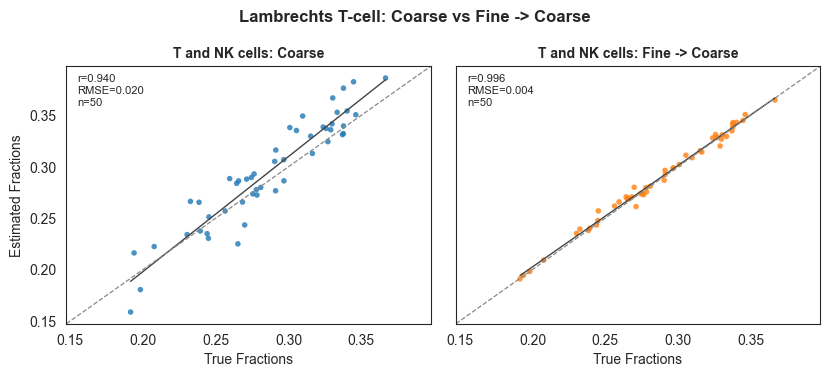

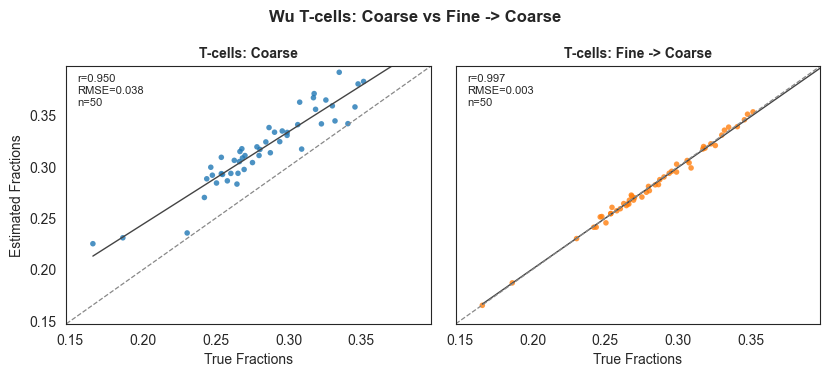

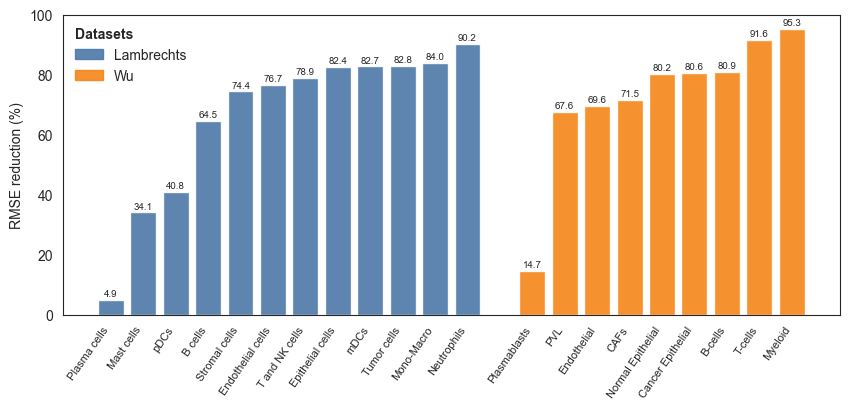

In [35]:
# New 2-panel figure:
# (A) Lambrechts T-cell scatter (Coarse vs Fine -> Coarse)
# (B) RMSE reduction per coarse cell type for Lambrechts and Wu

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

sns.set_style('white')

def _rmse_by_cell_type(eval_df):
    cols = ['Estimated Fractions', 'True Fractions']
    return eval_df.groupby('Cell type')[cols].apply(
        lambda d: np.sqrt(np.mean((d['Estimated Fractions'] - d['True Fractions']) ** 2))
    )

def _pick_t_cell_label(labels):
    labels = [x for x in labels if isinstance(x, str)]
    if not labels:
        return None
    nk_pref = [x for x in labels if ('t' in x.lower() and 'nk' in x.lower())]
    if nk_pref:
        return sorted(nk_pref, key=lambda x: x.lower())[0]
    t_pref = [x for x in labels if 't' in x.lower()]
    if t_pref:
        return sorted(t_pref, key=lambda x: x.lower())[0]
    return None

def _plot_t_scatter(ax, cdf, title, color, x0, x1):
    ax.scatter(
        cdf['True Fractions'],
        cdf['Estimated Fractions'],
        s=16,
        alpha=0.8,
        color=color,
        edgecolors='none',
    )
    if len(cdf) >= 2:
        sns.regplot(
            data=cdf,
            x='True Fractions',
            y='Estimated Fractions',
            scatter=False,
            ci=None,
            color='#444444',
            line_kws={'linewidth': 1.0},
            ax=ax,
        )
        r_val, _ = pearsonr(cdf['True Fractions'], cdf['Estimated Fractions'])
        rmse_val = np.sqrt(np.mean((cdf['Estimated Fractions'] - cdf['True Fractions']) ** 2))
        note = f"r={r_val:.3f}\nRMSE={rmse_val:.3f}\nn={len(cdf)}"
    else:
        note = f"r=NA\nRMSE=NA\nn={len(cdf)}"

    ax.plot([x0, x1], [x0, x1], linestyle='--', color='#888888', linewidth=0.9)
    ax.set_xlim(x0, x1)
    ax.set_ylim(x0, x1)
    ax.grid(False)
    ax.set_title(title, fontsize=10, weight='bold')
    ax.annotate(note, xy=(0.03, 0.97), xycoords='axes fraction', va='top', fontsize=8)

def _rmse_reduction_percent(eval_coarse, eval_f2c):
    coarse_rmse = _rmse_by_cell_type(eval_coarse)
    f2c_rmse = _rmse_by_cell_type(eval_f2c)
    common = coarse_rmse.index.intersection(f2c_rmse.index)
    red = (1 - (f2c_rmse.loc[common] / coarse_rmse.loc[common])) * 100
    red = red.replace([np.inf, -np.inf], np.nan).dropna()
    return red.sort_values(ascending=True)

# --- Panel A: Lambrechts T-cell scatter (coarse vs fine->coarse) ---
coarse_labels = set(lambrechts_coarse_eval['Cell type'].dropna().unique())
f2c_labels = set(lambrechts_f2c_eval['Cell type'].dropna().unique())
shared_labels = sorted(coarse_labels.intersection(f2c_labels), key=lambda x: str(x).lower())
t_label = _pick_t_cell_label(shared_labels)

if t_label is None:
    raise ValueError('No Lambrechts T-cell label found in coarse vs fine->coarse overlap.')

lambrechts_t_coarse = lambrechts_coarse_eval[lambrechts_coarse_eval['Cell type'] == t_label].copy()
lambrechts_t_f2c = lambrechts_f2c_eval[lambrechts_f2c_eval['Cell type'] == t_label].copy()

wu_t_coarse = wu_coarse_eval[wu_coarse_eval['Cell type'] == 'T-cells'].copy()
wu_t_f2c = wu_f2c_eval[wu_f2c_eval['Cell type'] == 'T-cells'].copy()

all_vals = pd.concat([
    lambrechts_t_coarse[['True Fractions', 'Estimated Fractions']],
    lambrechts_t_f2c[['True Fractions', 'Estimated Fractions']],
], ignore_index=True)
lo = float(np.nanmin(all_vals.values))
hi = float(np.nanmax(all_vals.values))
span = hi - lo if hi > lo else 1.0
pad = 0.05 * span
x0, x1 = lo - pad, hi + pad

# --- Panel B: RMSE reduction per coarse type ---
red_lambrechts = _rmse_reduction_percent(lambrechts_coarse_eval, lambrechts_f2c_eval)
red_wu = _rmse_reduction_percent(wu_coarse_eval, wu_f2c_eval)

# Figure 1: Lambrechts T-cell scatter (two panels)
fig, (ax_a1, ax_a2) = plt.subplots(1, 2, figsize=(8.4, 3.8), sharex=True, sharey=True)
_plot_t_scatter(ax_a1, lambrechts_t_coarse, f'{t_label}: Coarse', '#1f77b4', x0, x1)
_plot_t_scatter(ax_a2, lambrechts_t_f2c, f'{t_label}: Fine -> Coarse', '#ff7f0e', x0, x1)
ax_a1.set_xlabel('True Fractions')
ax_a2.set_xlabel('True Fractions')
ax_a1.set_ylabel('Estimated Fractions')
ax_a2.set_ylabel('')
fig.suptitle('Lambrechts T-cell: Coarse vs Fine -> Coarse', fontsize=12, weight='bold')
plt.tight_layout()
plt.savefig('../figures/fig3_lambrechts_tcell_coarse_vs_f2c_scatter.pdf', dpi=300, bbox_inches='tight')
plt.show()


fig, (ax_a1, ax_a2) = plt.subplots(1, 2, figsize=(8.4, 3.8), sharex=True, sharey=True)
_plot_t_scatter(ax_a1, wu_t_coarse, f'T-cells: Coarse', '#1f77b4', x0, x1)
_plot_t_scatter(ax_a2, wu_t_f2c, f'T-cells: Fine -> Coarse', '#ff7f0e', x0, x1)
ax_a1.set_xlabel('True Fractions')
ax_a2.set_xlabel('True Fractions')
ax_a1.set_ylabel('Estimated Fractions')
ax_a2.set_ylabel('')
fig.suptitle('Wu T-cells: Coarse vs Fine -> Coarse', fontsize=12, weight='bold')
plt.tight_layout()
plt.savefig('../figures/fig3_wu_tcell_coarse_vs_f2c_scatter.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Figure 2: RMSE reduction by coarse cell type
fig, ax_b = plt.subplots(figsize=(8.6, 4.2))
x_pos, heights, bar_colors, labels = [], [], [], []
dataset_ranges = {}
dataset_colors = {
    'Lambrechts': '#4C78A8',
    'Wu': '#F58518',
}
pos = 0
for dataset_name, series in [
    ('Lambrechts', red_lambrechts),
    ('Wu', red_wu),
]:
    color = dataset_colors[dataset_name]
    start = pos
    for ct, value in series.items():
        x_pos.append(pos)
        heights.append(float(value))
        bar_colors.append(color)
        labels.append('Mono-Macro' if ct == 'Macrophages-Monocytes' else ct)
        pos += 1
    end = pos - 1
    dataset_ranges[dataset_name] = (start, end, color)
    pos += 1

ax_b.bar(x_pos, heights, color=bar_colors, alpha=0.9)
ax_b.set_xticks(x_pos)
ax_b.set_xticklabels(labels, rotation=55, ha='right', fontsize=8)
ax_b.set_ylabel('RMSE reduction (%)')
ax_b.grid(False)
for spine in ax_b.spines.values():
    spine.set_linewidth(0.8)

for xp, v in zip(x_pos, heights):
    va = 'bottom' if v >= 0 else 'top'
    y = v + 0.6 if v >= 0 else v - 0.6
    ax_b.text(xp, y, f'{v:.1f}', ha='center', va=va, fontsize=7)

ax_b.set_ylim(0, 100)

for dataset_name, (start, end, color) in dataset_ranges.items():
    if end + 1 in x_pos:
        ax_b.axvline(end + 0.5, color='#DDDDDD', linewidth=0.8)

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=dataset_colors[name], alpha=0.9, label=name)
    for name in ['Lambrechts', 'Wu']
]
legend = ax_b.legend(
    handles=legend_handles,
    title='Datasets',
    loc='upper left',
    frameon=False,
    alignment='left',
)
legend.get_title().set_fontweight('bold')
legend.get_title().set_ha('left')

plt.tight_layout()
plt.savefig('../figures/fig3_rmse_reduction_by_coarse_celltype_lambrechts_wu.pdf', dpi=300, bbox_inches='tight')
plt.show()


## Allen resolution Analysis

## Figure 3E

In [ ]:

adata_hao_sub = anndata.read_h5ad('../data/haoSub_adata.h5ad')

adata_hao_sub.obs.value_counts()

hoek_tpm = pd.read_csv('../data/fig4/spillover/real_bulk_spillover/hoek_purified/hoek_purified_tpm.csv', index_col=0)
linsley_tpm = pd.read_csv('../data/fig4/spillover/real_bulk_spillover/linsley_purified/linsley_purified_tpm.csv',
                          index_col=0)
# you can find a zipped version of the file under: https://figshare.com/account/articles/32521659
hao_tpm = pd.read_csv('../data/fig4/spillover/pseudo_bulk_spillover/HaoCleaned_spillover_sim/HaoCleaned_spillover_sim_tpm.csv', index_col=0)

In [ ]:
hoek_estimations, hoek_signatures = rp.rectangle(adata_hao_sub, hoek_tpm.T)
# save the esitmations
hoek_estimations.to_csv("../output/hoek_estimations.csv")
# save the error by genes
hoek_signatures.unkn_bulk_err.to_csv("../output/hoek_err.csv")

In [ ]:
linsley_estimations, linsley_signatures = rp.rectangle(adata_hao_sub, linsley_tpm.T)
linsley_estimations.to_csv("../data/fig4/spillover/real_bulk_spillover/linsley_purified/spillover_linsley_estimations_with_tpm.csv")

In [ ]:
hao_estimations, hao_signatures = rp.rectangle(adata_hao_sub, hao_tpm.T)
hao_estimations.to_csv(
    "../data/fig4/spillover/pseudo_bulk_spillover/HaoCleaned_spillover_sim/spillover_hao_estimations_with_tpm.csv")

# 3D

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
# Load the spatial data
spatial_df = pd.read_csv('../data/fig3/spillover_total.csv', index_col=0)

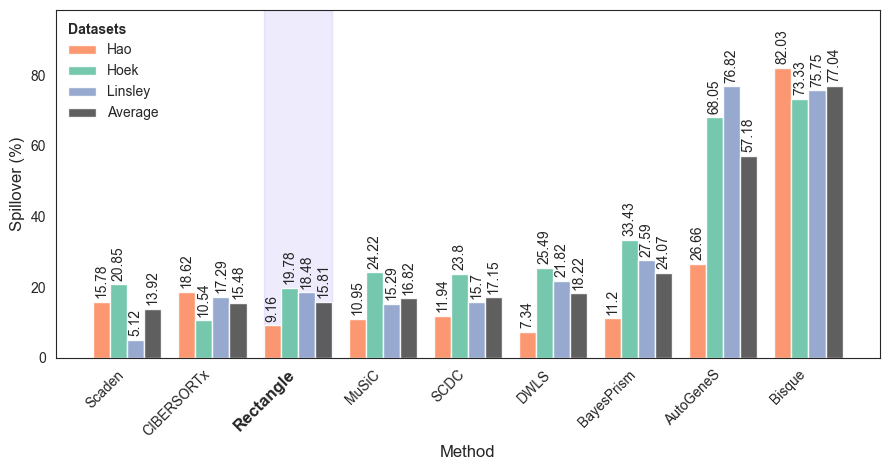


Spillover Summary:
              Hao   Hoek  Linsley  Average
Method                                    
Scaden      15.78  20.85    5.122   13.917
CIBERSORTx  18.62  10.54   17.290   15.483
Rectangle    9.16  19.78   18.480   15.807
MuSiC       10.95  24.22   15.290   16.820
SCDC        11.94  23.80   15.702   17.147
DWLS         7.34  25.49   21.824   18.218
BayesPrism  11.20  33.43   27.593   24.074
AutoGeneS   26.66  68.05   76.822   57.177
Bisque      82.03  73.33   75.751   77.037

Mean spillover per method:
Method
Scaden        13.9173
CIBERSORTx    15.4833
Rectangle     15.8067
MuSiC         16.8200
SCDC          17.1473
DWLS          18.2180
BayesPrism    24.0743
AutoGeneS     57.1773
Bisque        77.0370
dtype: float64


In [40]:
sns.set_style("white")
# Add average spillover and sort methods by average (lower is better)
spatial_df['Average'] = spatial_df[['Hao', 'Hoek', 'Linsley']].mean(axis=1)
method_tiebreak = {'Rectangle': 0, 'CIBERSORTx': 1, 'Cibersortx': 1}
spatial_df = (
    spatial_df
    .assign(
        _average_sort=lambda d: d['Average'].round(4),
        _method_name=spatial_df.index,
        _method_tiebreak=lambda d: d['_method_name'].map(method_tiebreak).fillna(2)
    )
    .sort_values(['_average_sort', '_method_tiebreak', '_method_name', 'Average'])
    .drop(columns=['_average_sort', '_method_name', '_method_tiebreak'])
)

spatial_df = spatial_df*100
# Create figure
fig, ax = plt.subplots(figsize=(9, 4.8))

# Grouped bar chart
datasets = ['Hao', 'Hoek', 'Linsley', 'Average']
colors = ['#FC8D62', '#66C2A5', '#8DA0CB', '#4D4D4D']

methods = spatial_df.index.tolist()
x = np.arange(len(methods))
width = 0.2

# Soft, eye-friendly color palette

for i, dataset in enumerate(datasets):
    offset = width * (i - (len(datasets) - 1) / 2)
    bars = ax.bar(x + offset, spatial_df[dataset], width, label=dataset, color=colors[i], alpha=0.9)
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 1,
            f'{round(height, 2)}',
            ha='center',
            va='bottom',
            fontsize=10,
            rotation=90
        )

# Highlight Rectangle with a vertical span and bold x-label
if 'Rectangle' in methods:
    rect_idx = methods.index('Rectangle')
    ax.axvspan(rect_idx - 0.4, rect_idx + 0.4, alpha=0.12, color='#6C5CE7', zorder=0)

    # Make Rectangle label bold
    labels = ax.get_xticklabels()
    labels[rect_idx].set_weight('bold')
    labels[rect_idx].set_fontsize(12)

ax.set_xlabel('Method', fontsize=12)
ax.set_ylabel('Spillover (%)', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(methods, rotation=45, ha='right')
legend = ax.legend(title='Datasets', loc='upper left', frameon=False, alignment='left')
legend.get_title().set_fontweight('bold')
legend.get_title().set_ha('left')
y_max = spatial_df[datasets].to_numpy().max()
ax.set_ylim(0, y_max * 1.2)
# Remove grid lines
ax.grid(False)

plt.tight_layout()
plt.savefig('../figures/fig3a_spatial_spillover.pdf', dpi=300, bbox_inches='tight')
plt.show()

print("\nSpillover Summary:")
print(spatial_df.round(3))
print("\nMean spillover per method:")
print(spatial_df[['Hao', 'Hoek', 'Linsley']].mean(axis=1).round(4).sort_values())


In [ ]:
## circle plot